# Isolation Forest: Finding Malignant Outliers Among Benign Samples

**Family:** Unsupervised learning | **Level:** Intermediate | **Dataset:** `breast_cancer` | **Runs on:** CPU, about 1 minute(s)

Isolate anomalies with random splits and score by path length.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- Why anomalies are isolated in few splits
- How the anomaly score is normalised
- How to evaluate anomaly detection with rare labels
- How contamination affects the threshold

**Prerequisites:**

- Distances and vectors
- Standardising features

**Skills you will have afterwards:**

- Pick settings without labels
- Check stability
- Compare with a reference labelling

## 2. Real-World Problem

**Context.** Screening systems look for rare abnormal cases in a mostly normal population.

**The problem.** Treat benign tumours as normal and a small share of malignant ones as anomalies, then rank rows without using labels for fitting.

**Why it matters.** A ranking lets reviewers inspect the most unusual rows first.

**Why machine learning.** Anomalies are rare and labels are scarce.

**Why this algorithm.** Isolation Forest is fast and needs no distance computation.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Isolation Forest

- **Type:** foundational paper
- **Authors:** Liu, F. T., Ting, K. M. and Zhou, Z. H.
- **Year and venue:** 2008, IEEE ICDM 2008, pp. 413-422
- **DOI or URL:** https://doi.org/10.1109/ICDM.2008.17
- **Verification:** Crossref 2026-11-17
- **Research objective:** Detect anomalies by how easily they are isolated.
- **Methodology:** Random trees with random splits. Anomalies have shorter average path length.
- **Dataset:** Benchmark anomaly datasets listed in the paper.
- **Main findings:** Linear time and low memory with competitive detection.
- **Limitations:** Axis parallel splits struggle with some local anomalies.

### LOF: identifying density-based local outliers

- **Type:** foundational paper
- **Authors:** Breunig, M. M., Kriegel, H. P., Ng, R. T. and Sander, J.
- **Year and venue:** 2000, ACM SIGMOD Record 29(2):93-104
- **DOI or URL:** https://doi.org/10.1145/335191.335388
- **Verification:** Crossref 2026-11-17
- **Research objective:** Score how isolated a point is relative to its neighbourhood.
- **Methodology:** Compare local reachability density of a point with that of its neighbours.
- **Dataset:** Synthetic data and NHL player statistics.
- **Main findings:** Finds local outliers that global distance rules miss.
- **Limitations:** Needs the neighbourhood size k and scales poorly in high dimensions.

**Relationship to this notebook.** Liu, Ting and Zhou introduce Isolation Forest. Breunig et al. introduce LOF, used here as a comparison. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Isolation tree.** Pick a random feature and a random split value between its minimum and maximum, recurse until each point is alone.

**Path length** $h(x)$ is the number of splits to isolate $x$. Anomalies have short paths.

**Score.** $s(x,n) = 2^{-E[h(x)]/c(n)}$ with $c(n) = 2H(n-1) - 2(n-1)/n$ and $H$ the harmonic number. Scores near 1 are anomalies, below 0.5 are normal.

**Limits.** Axis parallel splits, many irrelevant features dilute the signal.

## 5. Dataset Introduction

**Breast Cancer Wisconsin (Diagnostic)**, UCI, licence CC BY 4.0, DOI 10.24432/C5DW2B. 569 rows, 30 numeric features (mean, standard error and worst value of ten nucleus properties computed from digitised fine needle aspirate images). Target `malignant` (1 malignant, 0 benign). No missing values. Limits: one institution, small sample.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from ml_lab.data import load_dataset
from ml_lab.evaluation import internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "isolation_forest"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

bundle = load_dataset("breast_cancer")
X_raw = bundle.X
y_true = bundle.y          # evaluation only
print("shape:", X_raw.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
shape: (569, 30)


,source
title,Breast Cancer Wisconsin (Diagnostic)
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/17/breast+...
license,CC BY 4.0
doi,10.24432/C5DW2B
rows,569
features,30
limits,"Single institution, small sample, features com..."


## 6. Exploratory Data Analysis

We check size, missing values, label balance and feature relations. The reference labels are used for evaluation only, never for fitting. 

Rows and columns: (569, 30)
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


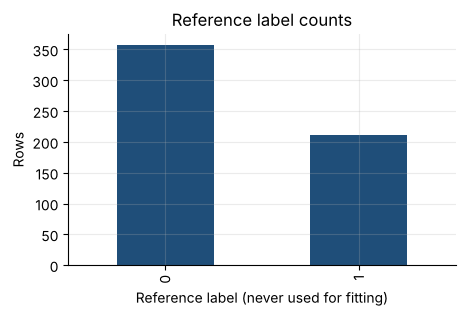

Mean absolute correlation between features: 0.382


In [2]:
print("Rows and columns:", X_raw.shape)
print("Missing values:", int(X_raw.isna().sum().sum()))
display(X_raw.describe().T.head(15).round(3))
fig, ax = plt.subplots(figsize=(5, 3))
pd.Series(y_true).value_counts().sort_index().plot.bar(ax=ax)
ax.set_xlabel("Reference label (never used for fitting)"); ax.set_ylabel("Rows"); ax.set_title("Reference label counts")
plt.show()
corr = X_raw.corr().abs().to_numpy(copy=True)
np.fill_diagonal(corr, 0)
print("Mean absolute correlation between features:", round(float(corr.mean()), 3))

## 7. Data Preprocessing

We keep all 357 benign rows (normal) and a random 5 percent of the benign count in malignant rows (about 18 anomalies). Features are standardised with a scaler fitted on the training part. 70 percent of rows train the detector, 30 percent are scored. The label is used only to evaluate the ranking.

In [3]:
from sklearn.model_selection import train_test_split
rng = np.random.default_rng(SEED)
benign = np.where(y_true.values == 0)[0]
malignant = rng.choice(np.where(y_true.values == 1)[0], int(0.05 * len(benign)), replace=False)
rows = np.sort(np.r_[benign, malignant])
Xs, ys = X_raw.values[rows], y_true.values[rows]
X_tr, X_te, y_tr, y_te = train_test_split(Xs, ys, test_size=0.3, stratify=ys, random_state=SEED)
scaler = StandardScaler().fit(X_tr)
X_tr, X_te = scaler.transform(X_tr), scaler.transform(X_te)
print("rows:", len(rows), "| anomalies:", int(ys.sum()), "| test anomalies:", int(y_te.sum()))

rows: 374 | anomalies: 17 | test anomalies: 5


## 8. Algorithm Implementation

### 8.1 Concept

Rows far from the crowd are separated by chance splits after few steps. Averaging many random trees makes the length stable.

### 8.2 Python implementation from scratch

A small isolation forest in NumPy, scored with the normalised path length.

In [4]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
def c_factor(n):
    return 0.0 if n <= 1 else 2 * (np.log(n - 1) + 0.5772156649) - 2 * (n - 1) / n
def build(Xs_, depth, limit, rng):
    if depth >= limit or len(Xs_) <= 1:
        return ("leaf", len(Xs_))
    j = rng.integers(Xs_.shape[1])
    lo, hi = Xs_[:, j].min(), Xs_[:, j].max()
    if lo == hi:
        return ("leaf", len(Xs_))
    t = rng.uniform(lo, hi)
    m = Xs_[:, j] < t
    return ("node", j, t, build(Xs_[m], depth + 1, limit, rng), build(Xs_[~m], depth + 1, limit, rng))
def path(tree, x, d=0):
    if tree[0] == "leaf":
        return d + c_factor(tree[1])
    return path(tree[3] if x[tree[1]] < tree[2] else tree[4], x, d + 1)
rng = np.random.default_rng(SEED)
psi = 128
limit = int(np.ceil(np.log2(psi)))
trees = [build(X_tr[rng.choice(len(X_tr), min(psi, len(X_tr)), replace=False)], 0, limit, rng) for _ in range(100)]
mean_path = np.array([np.mean([path(t, x) for t in trees]) for x in X_te])
score_mine = 2 ** (-mean_path / c_factor(min(psi, len(X_tr))))
ref = IsolationForest(n_estimators=100, max_samples=128, random_state=SEED).fit(X_tr)
print("ROC-AUC scratch:", round(roc_auc_score(y_te, score_mine), 3), "| sklearn:", round(roc_auc_score(y_te, -ref.score_samples(X_te)), 3))

ROC-AUC scratch: 0.994 | sklearn: 0.978


### 8.3 Library implementation

scikit-learn and scipy provide tested implementations.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `n_estimators` | Number of trees. |
| `max_samples` | Rows per tree. |
| `contamination` | Expected anomaly share, sets the threshold only. |
| `max_features` | Features per tree. |

## 9. Model Training

We pick the number of trees from a small grid by the stability of the ranking (rank correlation between two seeds). Anomaly labels are not used.

In [5]:
from scipy.stats import spearmanr
rows = []
for n in [25, 100, 300]:
    a = IsolationForest(n_estimators=n, random_state=0).fit(X_tr).score_samples(X_te)
    b = IsolationForest(n_estimators=n, random_state=1).fit(X_tr).score_samples(X_te)
    rows.append({"n_estimators": n, "rank_correlation_between_seeds": spearmanr(a, b)[0]})
stab = pd.DataFrame(rows).set_index("n_estimators")
display(stab.round(4))
model = IsolationForest(n_estimators=300, random_state=SEED).fit(X_tr)
score = -model.score_samples(X_te)

,rank_correlation_between_seeds
n_estimators,
25,0.7665
100,0.9323
300,0.9884


## 10. Evaluation

ROC-AUC and PR-AUC of the anomaly score against the held out labels, compared with a random ranking and with Local Outlier Factor. With about 5 test anomalies, these numbers are very uncertain, so we add a bootstrap interval.

In [6]:
from sklearn.metrics import average_precision_score
from sklearn.neighbors import LocalOutlierFactor
lof = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(X_tr)
score_lof = -lof.score_samples(X_te)
rng = np.random.default_rng(SEED)
boot = []
for _ in range(500):
    i = rng.integers(0, len(y_te), len(y_te))
    if y_te[i].sum() > 0 and y_te[i].sum() < len(i):
        boot.append(roc_auc_score(y_te[i], score[i]))
METRICS = {"ROC_AUC": roc_auc_score(y_te, score), "PR_AUC": average_precision_score(y_te, score), "PR_AUC_random": float(y_te.mean()),
           "ROC_AUC_LOF": roc_auc_score(y_te, score_lof), "ROC_AUC_boot_low": float(np.percentile(boot, 2.5)), "ROC_AUC_boot_high": float(np.percentile(boot, 97.5))}
CONFIG = {"n_estimators": 300, "anomaly_share": 0.05}
EXTRA = {"test_rows": int(len(y_te)), "test_anomalies": int(y_te.sum()), "stability": stab.round(4).reset_index().to_dict("records")}

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="unsupervised", algorithm="IsolationForest", dataset="breast_cancer",
                          task="clustering", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

saved: /home/claude/open-python/experiments/results/isolation_forest.json


,metric
ROC_AUC,0.9833
PR_AUC,0.7643
PR_AUC_random,0.0442
ROC_AUC_LOF,0.9759
ROC_AUC_boot_low,0.9508
ROC_AUC_boot_high,1.0000


## 11. Visualization

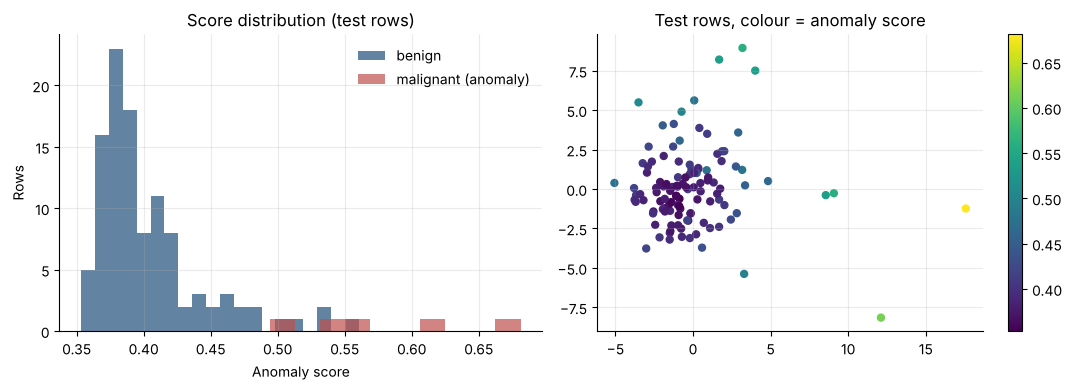

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(score[y_te == 0], bins=20, alpha=0.7, label="benign"); axes[0].hist(score[y_te == 1], bins=10, alpha=0.7, label="malignant (anomaly)")
axes[0].set_xlabel("Anomaly score"); axes[0].set_ylabel("Rows"); axes[0].legend(); axes[0].set_title("Score distribution (test rows)")
Z = PCA(2, random_state=SEED).fit(X_tr).transform(X_te)
sc = axes[1].scatter(Z[:, 0], Z[:, 1], c=score, cmap="viridis", s=25); axes[1].set_title("Test rows, colour = anomaly score"); plt.colorbar(sc, ax=axes[1])
plt.tight_layout(); save_figure(fig, NOTEBOOK_ID, "overview"); plt.show()

## 12. Interpretation

Which features make the top ranked rows unusual: compare their standardised values with the training mean.

In [8]:
top = np.argsort(score)[-3:]
names = np.array(X_raw.columns)
for i in top:
    order = np.argsort(-np.abs(X_te[i]))[:3]
    print("row", i, "label", int(y_te[i]), "| most unusual features:", dict(zip(names[order], np.round(X_te[i][order], 1))))

row 48 label 0 | most unusual features: {'smoothness error': np.float64(5.5), 'mean fractal dimension': np.float64(4.9), 'worst fractal dimension': np.float64(3.7)}
row 112 label 1 | most unusual features: {'worst area': np.float64(6.0), 'mean area': np.float64(5.9), 'worst radius': np.float64(4.9)}
row 23 label 1 | most unusual features: {'worst compactness': np.float64(5.8), 'mean concavity': np.float64(5.1), 'mean concave points': np.float64(5.0)}


## 13. Experiments and Challenges

### Experiment 1: Contamination and threshold

The contamination parameter only sets the cut. Check precision and recall at three values.

In [9]:
from sklearn.metrics import precision_score, recall_score
for c in [0.02, 0.05, 0.1]:
    thr = np.quantile(score, 1 - c)
    pred = (score >= thr).astype(int)
    print(f"contamination={c}: precision {precision_score(y_te, pred, zero_division=0):.2f}, recall {recall_score(y_te, pred):.2f}")

contamination=0.02: precision 0.67, recall 0.40
contamination=0.05: precision 0.50, recall 0.60
contamination=0.1: precision 0.42, recall 1.00


### Experiment 2: Subsample size

max_samples per tree.

In [10]:
for ms in [32, 64, 128, 256]:
    s = -IsolationForest(n_estimators=200, max_samples=ms, random_state=SEED).fit(X_tr).score_samples(X_te)
    print(f"max_samples={ms}: ROC-AUC {roc_auc_score(y_te, s):.3f}")

max_samples=32: ROC-AUC 0.976


max_samples=64: ROC-AUC 0.981


max_samples=128: ROC-AUC 0.983


max_samples=256: ROC-AUC 0.989


### Experiment 3: Irrelevant features

Add noise columns and watch the score fall.

In [11]:
rng = np.random.default_rng(SEED)
for extra in [0, 30, 100]:
    tr = np.c_[X_tr, rng.normal(size=(len(X_tr), extra))]; te = np.c_[X_te, rng.normal(size=(len(X_te), extra))]
    s = -IsolationForest(n_estimators=200, random_state=SEED).fit(tr).score_samples(te)
    print(f"{extra} noise columns: ROC-AUC {roc_auc_score(y_te, s):.3f}")

0 noise columns: ROC-AUC 0.989


30 noise columns: ROC-AUC 0.980


100 noise columns: ROC-AUC 0.981


### Exercises for learners

1. Repeat with `SEED = 7` and report which numbers move.
2. Change the number of rows by sampling 50 percent and compare the result.
3. Add pure noise columns and watch the internal scores.

## 14. Research Discussion

Liu et al. report that Isolation Forest ranks anomalies well with low cost. Our test has few anomalies, so the interval is wide and we cannot rank it against LOF with confidence.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Repeat the anomaly sampling many times and report the average, and use extended isolation forests.

**Research limitations.** One dataset and one seed for the headline numbers. The anomaly set is constructed by sampling malignant rows, so this is a proxy for anomaly detection, not a real screening study.

## 15. Summary and Further Reading

**Key takeaways**

- Anomalies are isolated early.
- Contamination only sets a threshold.
- With rare labels report intervals.

**Use cases.** Fraud screening, sensor monitoring, data cleaning.

**Limitations.** Axis parallel splits.

**Recommended next notebook.** Reinforcement learning basics.

**Further reading.** See `references.md` in this folder.